# Lab 19: Hierarchical and Time-Varying MMM

This lab works through the two extensions Chapter 19 describes.
The first part fits a hierarchical model to the Sedge Shoes regional panel, with each channel's effect partially pooled across the 18 regions rather than fitted to the national aggregate used in earlier labs.
The second part lets one channel's effect drift over time through a random walk, first on Sedge as recorded and then on a version of the data in which an effect really does decline.
It accompanies Chapter 19 of the book Marketing Mix Modelling.

In [1]:
import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pymc as pm

from mmm_book import RANDOM_SEED
from mmm_book.plotting import mmm_style
from mmm_book.reference import (
    BETA_PRIOR_SHARE,
    REVENUE_SCALE,
    build_controls,
    build_events,
    build_features,
    build_seasonality,
    build_treatments,
    national_aggregate,
)
from mmm_book.sedge import CHANNELS, generate_sedge, ground_truth_contributions

mmm_style()


def check(idata):
    n_divergent = int(idata.sample_stats["diverging"].sum())
    r_hat = float(az.summary(idata, kind="diagnostics")["r_hat"].max())
    print(f"divergent transitions: {n_divergent}, largest r_hat: {r_hat:.3f}")

## Part 1: partial pooling across regions

### Per-region features

The regional model keeps the 18 Sedge regions separate.
`build_features` and the control builders are applied to each region's own weekly slice, so each region gets its own adstocked, saturated feature per channel and its own price, promotion, distribution, stock, weather and category series.
Regions are sorted by number, so `region_2` comes before `region_10`.

In [2]:
df = generate_sedge()
regions = sorted(df["region"].unique(), key=lambda r: int(r.split("_")[1]))
frames = {r: df[df["region"] == r].sort_values("week") for r in regions}


def by_region(builder):
    """Stack a builder's output as (region, term, week), with the term names."""
    built = {r: builder(frames[r]) for r in regions}
    names = list(built[regions[0]])
    return names, np.stack([np.stack([built[r][n] for n in names]) for r in regions])


_, feat_arr = by_region(build_features)  # (region, channel, week)
control_names, z_arr = by_region(build_controls)  # (region, control, week)
_, promo_arr = by_region(build_treatments)  # (region, 1, week)
y_arr = np.stack([frames[r]["revenue"].to_numpy(dtype=float) / REVENUE_SCALE for r in regions])

first = frames[regions[0]]
season = build_seasonality(first)
launch = build_events(first)["launch"]
week = first["week"].to_numpy(dtype=float)
week_c = (week - week.mean()) / week.std()

print(f"regions: {', '.join(regions)}")
print(f"feature array shape (region, channel, week): {feat_arr.shape}")

regions: region_0, region_1, region_2, region_3, region_4, region_5, region_6, region_7, region_8, region_9, region_10, region_11, region_12, region_13, region_14, region_15, region_16, region_17
feature array shape (region, channel, week): (18, 5, 156)


### The hierarchical model

The model has the hybrid form of the case-study model (Chapter 15's box on how it differs).
Its non-media part is multiplicative: each region's own sales level is scaled by a shared trend, seasonality and launch effect (the baseline) and by a shared promotion effect and controls.
A hot week or a discount therefore moves a large region by more pounds than a small one, and the media are added in pounds on top.

The channel effects are partially pooled.
Each channel has a typical regional effect, `mu_ch`, and each region's beta ($\beta_{g,m}$) is that typical effect multiplied by a regional factor, $\exp(\tau_m z_{g,m})$, with $z_{g,m} \sim \text{Normal}(0, 1)$.
This is the non-centred form of Chapter 18: the sampler works with the standardised scores `z`, and each region's beta is rebuilt from them.
`tau_ch` ($\tau_m$) is the channel's regional spread on a multiplicative scale, and its prior, HalfNormal(0.15), is the one Chapter 17 discusses and the case-study model uses: a typical region's effect sits within about 10 to 15 per cent of the channel's typical effect.
As in the other labs, each beta is a region's average weekly contribution, and each channel's adstock and saturation are fixed at the values the data were built with.
The priors follow Lab 17: `mu_ch` is HalfNormal with a scale of a tenth of a region's mean weekly revenue, and the trend, seasonality, launch, promotion and control coefficients, which act on the log scale, have a prior scale equal to revenue's coefficient of variation.

In [3]:
coords = {"region": regions, "channel": CHANNELS, "control": control_names}
cv = float((y_arr.std(axis=1) / y_arr.mean(axis=1)).mean())

with pm.Model(coords=coords) as hierarchical_model:
    level = pm.Normal("level", mu=np.log(y_arr.mean(axis=1)), sigma=0.5, dims="region")
    trend = pm.Normal("trend", 0, cv)
    season_a = pm.Normal("season_a", 0, cv)
    season_b = pm.Normal("season_b", 0, cv)
    omega_launch = pm.Normal("omega_launch", 0, cv)
    delta_promo = pm.Normal("delta_promo", 0, cv)
    gamma = pm.Normal("gamma", 0, cv, dims="control")
    log_baseline = (
        level[:, None]
        + trend * week_c
        + season_a * season["sin"]
        + season_b * season["cos"]
        + omega_launch * launch
        + delta_promo * promo_arr[:, 0, :]
        + (gamma[None, :, None] * z_arr).sum(axis=1)
    )

    mu_ch = pm.HalfNormal("mu_ch", sigma=BETA_PRIOR_SHARE * float(y_arr.mean()), dims="channel")
    tau_ch = pm.HalfNormal("tau_ch", sigma=0.15, dims="channel")
    z = pm.Normal("z", 0.0, 1.0, dims=("region", "channel"))
    beta = pm.Deterministic(
        "beta", mu_ch[None, :] * pm.math.exp(tau_ch[None, :] * z), dims=("region", "channel")
    )

    mu = pm.math.exp(log_baseline) + (beta[:, :, None] * feat_arr).sum(axis=1)
    sigma = pm.HalfNormal("sigma", sigma=float(y_arr.std()))
    pm.Normal("y", mu=mu, sigma=sigma, observed=y_arr)

print(hierarchical_model.str_repr())

       level ~ Normal(<constant>, 0.5)
       trend ~ Normal(0, 0.224)
    season_a ~ Normal(0, 0.224)
    season_b ~ Normal(0, 0.224)
omega_launch ~ Normal(0, 0.224)
 delta_promo ~ Normal(0, 0.224)
       gamma ~ Normal(0, 0.224)
       mu_ch ~ HalfNormal(0, 0.00512)
      tau_ch ~ HalfNormal(0, 0.15)
           z ~ Normal(0, 1)
       sigma ~ HalfNormal(0, 0.0123)
        beta = Deterministic(f(mu_ch, z, tau_ch))
           y ~ Normal(f(beta, gamma, delta_promo, omega_launch, season_b, level, season_a, trend), sigma)


### Sampling

Four chains of 1,000 draws after 1,000 warm-up steps at a target acceptance rate of 0.95, as in every lab, run in parallel on four cores.
The diagnostics are checked before anything is read.

In [4]:
with hierarchical_model:
    idata = pm.sample(
        draws=1000,
        tune=1000,
        chains=4,
        cores=4,
        target_accept=0.95,
        random_seed=RANDOM_SEED,
        progressbar=False,
    )
check(idata)

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [level, trend, season_a, season_b, omega_launch, delta_promo, gamma, mu_ch, tau_ch, z, sigma]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 27 seconds.


divergent transitions: 0, largest r_hat: 1.006


In [5]:
summary = az.summary(idata, var_names=["mu_ch", "tau_ch"], ci_prob=0.9)
print(summary)

contributions = ground_truth_contributions()
print("\ntrue average weekly contribution per region (GBPm):")
for ch in CHANNELS:
    print(f"  {ch:<8}{contributions[ch].mean() / REVENUE_SCALE:.4f}")

                     mean        sd eti90_lb eti90_ub ess_bulk ess_tail r_hat mcse_mean  mcse_sd
mu_ch[tv]        0.003557   9.2e-05   0.0034   0.0037     6124     3420  1.00   1.2e-06  1.5e-06
mu_ch[search]     0.00354   0.00048   0.0028   0.0043     1639     2239  1.00   1.2e-05  6.6e-06
mu_ch[meta]       0.00412   0.00085   0.0027   0.0055     1479     1918  1.00   2.2e-05  1.4e-05
mu_ch[youtube]      0.001   0.00048  0.00025   0.0018     2734     1904  1.00   8.7e-06  7.3e-06
mu_ch[ooh]       0.001526  0.000207   0.0012   0.0019     4267     2697  1.00   3.2e-06  3.4e-06
tau_ch[tv]          0.046    0.0285   0.0046    0.096     1558     1754  1.00   0.00069  0.00037
tau_ch[search]      0.186     0.095    0.031     0.34     1598     1832  1.00    0.0023   0.0012
tau_ch[meta]        0.096      0.07   0.0077     0.23     2611     2429  1.00    0.0013  0.00099
tau_ch[youtube]     0.105     0.083   0.0076     0.27     4973     2584  1.00    0.0011   0.0014
tau_ch[ooh]         0.119     

The typical regional effects land close to the truth for Television and OOH, with Search a little low but well inside its interval.
Meta is high and YouTube low, the paid-social split that the shared budget makes hard to pin down in every lab.
Each spread `tau_ch` is small, with posterior means between about 0.05 and 0.19: the regions really are alike in this synthetic world (the generator gives every region the same average contribution), and the model has learned that from the data.

### Showing the pooling

For each channel, the 18 region betas cluster around the channel's typical effect rather than spreading out to whatever an independent per-region fit would find.
That clustering is partial pooling at work: a region with a noisy media history borrows strength from the other regions through the shared prior, instead of fitting its own beta in isolation.

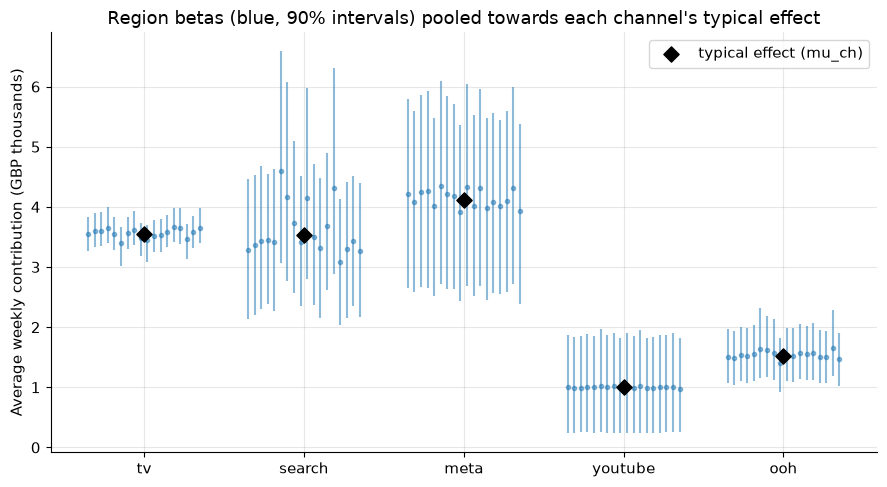

In [6]:
post = idata.posterior
beta_mean = post["beta"].mean(dim=("chain", "draw")) * 1e3
beta_lo = post["beta"].quantile(0.05, dim=("chain", "draw")) * 1e3
beta_hi = post["beta"].quantile(0.95, dim=("chain", "draw")) * 1e3
mu_mean = post["mu_ch"].mean(dim=("chain", "draw")) * 1e3

x = np.arange(len(CHANNELS))
offsets = np.linspace(-0.35, 0.35, len(regions))

fig, ax = plt.subplots()
for i, r in enumerate(regions):
    m = beta_mean.sel(region=r).to_numpy()
    lo = beta_lo.sel(region=r).to_numpy()
    hi = beta_hi.sel(region=r).to_numpy()
    ax.errorbar(x + offsets[i], m, yerr=[m - lo, hi - m], fmt="o", ms=3, color="C0", alpha=0.5)
ax.scatter(
    x, mu_mean.to_numpy(), marker="D", s=60, color="black", zorder=5, label="typical effect (mu_ch)"
)
ax.set_xticks(x)
ax.set_xticklabels(CHANNELS)
ax.set_ylabel("Average weekly contribution (GBP thousands)")
ax.set_title("Region betas (blue, 90% intervals) pooled towards each channel's typical effect")
ax.legend()
fig.tight_layout()

## Part 2: a time-varying effect

Chapter 19 describes the extension Sedge prepared for Meta: multiply the channel's effect by a slowly drifting factor that follows a random walk with small steps, so the factor can move a long way over two years but cannot jump from week to week.
`fit_drifting` builds the national reference model of Lab 15 with one channel's beta multiplied by such a factor, $\beta_{m,t} = \beta_m \exp(r_t)$.
The walk $r_t$ takes one step every four weeks, each step Normal with standard deviation 0.05 (written non-centred, as `steps`), so over two years the factor's prior spread is about a quarter on the log scale: a fall from 1 to 0.6 is plausible, a weekly jump is not.
The walk is centred so the factor averages 1 over the three years, which keeps $\beta_m$ the channel's average weekly contribution.
The fits use a target acceptance rate of 0.99: the 38 standardised steps make a sharply curved posterior near a flat walk, and at 0.95 the sampler occasionally overshoots there and reports a divergence.

In [7]:
nat = national_aggregate(df)
feat = build_features(nat)
nat_season = build_seasonality(nat)
nat_events = build_events(nat)
nat_treatments = build_treatments(nat)
nat_controls = build_controls(nat)
nat_week = nat["week"].to_numpy(dtype=float)
nat_week_c = (nat_week - nat_week.mean()) / nat_week.std()

STEP_SD = 0.05
BLOCK_WEEKS = 4
block = (nat_week // BLOCK_WEEKS).astype(int)
n_blocks = int(block.max()) + 1


def fit_drifting(y, channel):
    """The Lab 15 national model with `channel`'s beta drifting as a random walk."""
    scale = y.std()
    with pm.Model():
        intercept = pm.Normal("intercept", mu=y.mean(), sigma=scale)
        trend = pm.Normal("trend", 0, scale)
        season_a = pm.Normal("season_a", 0, scale)
        season_b = pm.Normal("season_b", 0, scale)
        omega = {k: pm.Normal(f"omega_{k}", 0, scale) for k in nat_events}
        delta = {k: pm.Normal(f"delta_{k}", 0, scale) for k in nat_treatments}
        gamma = {k: pm.Normal(f"gamma_{k}", 0, scale) for k in nat_controls}
        betas = {
            ch: pm.HalfNormal(f"beta_{ch}", sigma=BETA_PRIOR_SHARE * y.mean()) for ch in CHANNELS
        }
        steps = pm.Normal("steps", 0, 1, shape=n_blocks - 1)
        walk = pm.math.concatenate([[0.0], pm.math.cumsum(STEP_SD * steps)])
        log_factor = walk[block] - walk[block].mean()
        factor = pm.Deterministic("factor", pm.math.exp(log_factor))
        mu = (
            intercept
            + trend * nat_week_c
            + season_a * nat_season["sin"]
            + season_b * nat_season["cos"]
            + sum(omega[k] * nat_events[k] for k in nat_events)
            + sum(delta[k] * nat_treatments[k] for k in nat_treatments)
            + sum(gamma[k] * nat_controls[k] for k in nat_controls)
            + sum(betas[ch] * feat[ch] for ch in CHANNELS if ch != channel)
            + betas[channel] * factor * feat[channel]
        )
        sigma = pm.HalfNormal("sigma", sigma=scale)
        pm.Normal("y", mu=mu, sigma=sigma, observed=y)
        fit = pm.sample(
            draws=1000,
            tune=1000,
            chains=4,
            cores=4,
            target_accept=0.99,
            random_seed=RANDOM_SEED,
            progressbar=False,
        )
    check(fit)
    return fit.posterior["factor"].to_numpy().reshape(-1, len(nat_week))

### Sedge as recorded: Meta

Meta was Sedge's candidate, because its creative strategy and audience targeting changed during the period.
In the generated data Meta's effect is stable, so a well-behaved time-varying model should find no drift.

In [8]:
y_recorded = nat["revenue"].to_numpy(dtype=float) / REVENUE_SCALE
factor_meta = fit_drifting(y_recorded, "meta")

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [intercept, trend, season_a, season_b, omega_launch, delta_promo, gamma_log_price, gamma_distribution, gamma_stock, gamma_temperature, gamma_rainfall, gamma_category, beta_tv, beta_search, beta_meta, beta_youtube, beta_ooh, steps, sigma]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 25 seconds.


divergent transitions: 0, largest r_hat: 1.005


### A world where an effect really declines: Television

To see the extension find a drift that is there, the next cell builds a version of the data in which Television's effect is stable for the first year and then falls steadily to 60 per cent of its starting level by the end of the third, the size of change Chapter 19 describes.
It subtracts the missing share of Television's true contribution (`ground_truth_contributions`) from revenue.
Television is the channel the national data identify best, so it shows the mechanism most clearly.

In [9]:
tv_true = df.assign(tv_c=contributions["tv"]).groupby("week")["tv_c"].sum().to_numpy()
drift = np.where(nat_week < 52, 1.0, 1.0 - 0.4 * (nat_week - 52) / (nat_week.max() - 52))
y_drifted = y_recorded - tv_true * (1.0 - drift) / REVENUE_SCALE
factor_tv = fit_drifting(y_drifted, "tv")

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [intercept, trend, season_a, season_b, omega_launch, delta_promo, gamma_log_price, gamma_distribution, gamma_stock, gamma_temperature, gamma_rainfall, gamma_category, beta_tv, beta_search, beta_meta, beta_youtube, beta_ooh, steps, sigma]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 30 seconds.


divergent transitions: 0, largest r_hat: 1.004


meta: first week 1.07 (0.84 to 1.37), last week 1.05 (0.79 to 1.34); true 1.00 and 1.00
tv: first week 1.34 (1.15 to 1.58), last week 0.86 (0.75 to 0.99); true 1.15 and 0.69


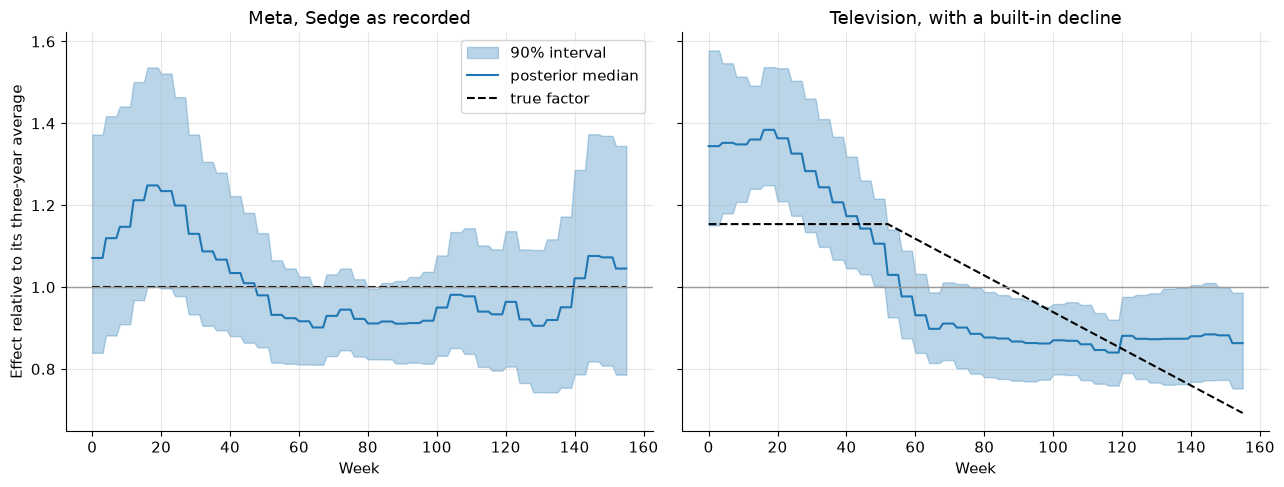

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
panels = [
    (axes[0], factor_meta, np.ones_like(nat_week), "Meta, Sedge as recorded"),
    (axes[1], factor_tv, drift / drift.mean(), "Television, with a built-in decline"),
]
for ax, draws, truth, title in panels:
    lo, med, hi = np.percentile(draws, [5, 50, 95], axis=0)
    ax.fill_between(nat_week, lo, hi, color="C0", alpha=0.3, label="90% interval")
    ax.plot(nat_week, med, color="C0", label="posterior median")
    ax.plot(nat_week, truth, color="black", linestyle="--", label="true factor")
    ax.axhline(1.0, color="0.6", linewidth=1)
    ax.set_title(title)
    ax.set_xlabel("Week")
axes[0].set_ylabel("Effect relative to its three-year average")
axes[0].legend()
fig.tight_layout()

for name, draws, truth in [
    ("meta", factor_meta, np.ones_like(nat_week)),
    ("tv", factor_tv, drift / drift.mean()),
]:
    lo, med, hi = np.percentile(draws[:, [0, -1]], [5, 50, 95], axis=0)
    print(
        f"{name}: first week {med[0]:.2f} ({lo[0]:.2f} to {hi[0]:.2f}), "
        f"last week {med[1]:.2f} ({lo[1]:.2f} to {hi[1]:.2f}); "
        f"true {truth[0]:.2f} and {truth[-1]:.2f}"
    )

On Sedge as recorded, Meta's factor wanders between about 0.9 and 1.25, and its 90 per cent band contains, or just touches, the flat line at 1 throughout.
Nothing there amounts to a drift, which is what Sedge's team concluded from the stable model's errors before deciding to leave the extension out.
The wandering itself is a warning: with a free factor, ordinary noise already looks like a gentle story about changing effectiveness.
With a decline built in, Television's factor falls from about 1.35 in the first week to about 0.86 in the last, a fall of about a third against the true 40 per cent, and its band leaves the flat line, so the extension finds a real change when the data contain one.
Its timing is smeared, though: it starts falling before week 52 and levels off early, because the walk's small steps resist sharp turns and the trend can absorb part of a steady decline.

## Takeaway

Hierarchy helps whenever there are several related units (regions, stores or brands) that each carry some information about a channel's effect but not enough on their own to estimate it reliably.
A region borrows strength from the others, and its estimate is pulled towards the group most where its own data are weakest.
It helps least when units are unrelated, when pooling introduces bias towards a mean that describes none of them.
Time variation borrows strength along time instead, from neighbouring weeks, and it is the riskier of the two: a factor allowed to move can absorb trend, noise or an omitted confounder and tell a persuasive story of changing effectiveness.
That is why Chapter 19 adds it only for a specific business hypothesis, checks first whether the stable model shows the failure it would fix, and wants external evidence before trusting the drift it finds.